# Portfolio backtest: gross vs net

This notebook runs the pre-registered design in `configs/portfolio.yaml`. The four signals are `lightgbm_h5_rank`, `B0_reversal_h5`, `B1_composite_h5` and `lightgbm_h21_rank`, each under three constructions: `decile_ls`, `neutral_volscaled` and `optimised`.

- **Tuning window:** 2007-01-03 to 2013-12-31. The optimiser's λs were chosen here, so every tuning-window number is in-sample for the λs.
- **Evaluation window:** 2014-01-02 to 2021-12-08. It was run once, with the frozen λs. The last positions are exited at the end of their labels, which is before `holdout_start` (2022-01-01).

All tables are read from `reports/portfolio/`, and the summary is in `reports/portfolio/SUMMARY.md`.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, "..")

OUT = Path("../reports/portfolio")
DATA = Path("../data/processed/portfolio")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_rows", 100)
read = lambda name: pd.read_csv(OUT / f"{name}.csv")

meta = json.loads((OUT / "run_metadata.json").read_text())
daily = pd.concat([pd.read_parquet(p) for p in sorted(DATA.glob("*/portfolio_daily_returns.parquet"))],
                  ignore_index=True)
daily = daily[(daily["tranche"] == "total") & (daily["scenario"] == "base")].copy()
daily["date"] = pd.to_datetime(daily["date"])
SPLIT = pd.Timestamp("2014-01-01")
starts = read("summary").query("scenario == 'base' and window == 'full'").set_index(["signal", "construction"])["start"]
daily = daily[[pd.Timestamp(starts[(s, c)]) <= d for s, c, d in zip(daily["signal"], daily["construction"], daily["date"])]]
series = {k: g.set_index("date").sort_index() for k, g in daily.groupby(["signal", "construction"])}
{"config_sha256": meta["config_sha256"], "last_research_date": meta["last_research_date"],
 "holdout_start": meta["holdout_start"]}

{'config_sha256': ['6e2e5c1a33960b5a6fe7af7010651d7f33ae2f9024ada4effa1f86990f1dff2d'],
 'last_research_date': '2021-11-30',
 'holdout_start': '2022-01-01'}

## Reconciliation

The test runs `decile_ls` on `B0_reversal_h5` with zero costs, one tranche and offset 0. Its returns should match the raw h=5 D10-D1 spread from `reports/models/decile_spreads.csv`.

The engine's mean differs by -7e-6 per period over 751 periods, and Sharpe is 0.5877 against 0.5883. All of the difference comes from 6 periods in which a leg holds a name with no label. Without those periods, the largest difference is 1e-16. At zero costs, gross equals net exactly for every construction.

In [2]:
display(read("reconciliation"))

,source,n_periods,mean,vol,sharpe,nw_t,max_abs_diff,periods_differing_1e-6,periods_with_missing_leg_labels,max_abs_diff_without_missing_labels,cost_sum,turnover_sum
0,reports/models/decile_spreads.csv,751,0.002904,0.035048,0.58832,2.176441,NaN,NaN,NaN,NaN,NaN,NaN
1,label_spread_recomputed,751,0.002904,0.035048,0.58832,2.176441,NaN,NaN,NaN,NaN,NaN,NaN
2,engine_decile_ls_zero_cost_one_tranche,751,0.002898,0.035003,0.58772,2.176097,NaN,NaN,NaN,NaN,NaN,NaN
3,engine_minus_label_per_period,751,-0.000007,0.000210,NaN,NaN,0.005549,6.0,6.0,9.540979e-17,NaN,NaN
4,zero_cost_gross_minus_net_decile_ls,4013,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,1310.273122
5,zero_cost_gross_minus_net_neutral_volscaled,4013,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,1056.579026
6,zero_cost_gross_minus_net_optimised,312,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,0.0,18.669245


## Headline

The headline compares `optimised` on `lightgbm_h5_rank` with B0 over the evaluation window, at $100m and base costs. **Net Sharpe is -0.00 (NW t -0.00), and B0's is -0.03 (t -0.07).** Neither number is different from zero.

The frozen λs for the headline are the corner of the grid (λ_risk=100, λ_tc=4). The book trades about 1.2× a year with 2.4% net vol. Its gross Sharpe is 0.14, and the break-even cost multiplier is 0.99. In the tuning window, where the λs are in-sample, the same choice had a net Sharpe of 0.35 (t 0.94).

In [3]:
display(read("headline"))
display(read("hyperparameters"))

,signal,construction,window,net_sharpe,net_nw_t,nw_lag,net_return_ann,net_vol_ann,gross_sharpe,annual_turnover,breakeven_cost_multiplier,start,end,n_days,tuning_window_net_sharpe_in_sample_lambdas,tuning_window_net_nw_t_in_sample_lambdas
0,lightgbm_h5_rank,optimised,evaluation,-0.001464,-0.004420,7,-0.000035,0.023873,0.135822,1.184854,0.989336,2014-01-02,2021-12-08,1999,0.345011,0.943979
1,B0_reversal_h5,optimised,evaluation,-0.025987,-0.065464,7,-0.001791,0.068929,0.263295,9.927237,0.910272,2014-01-02,2021-12-08,1999,0.447243,1.099971


,signal,horizon,grid_order,lambda_risk,lambda_tc,net_sharpe,config_sha256,lambda_risk_on_grid_edge,lambda_tc_on_grid_edge
0,lightgbm_h5_rank,5,15,100.0,4.0,0.345011,6e2e5c1a33960b5a6fe7af7010651d7f33ae2f9024ada4...,True,True
1,B0_reversal_h5,5,1,3.0,1.0,0.447243,6e2e5c1a33960b5a6fe7af7010651d7f33ae2f9024ada4...,True,False
2,B1_composite_h5,5,2,3.0,2.0,-0.136766,6e2e5c1a33960b5a6fe7af7010651d7f33ae2f9024ada4...,True,False
3,lightgbm_h21_rank,21,3,3.0,4.0,0.483996,6e2e5c1a33960b5a6fe7af7010651d7f33ae2f9024ada4...,True,True


### Cumulative gross and net P&L

The dashed line marks the split between the tuning and evaluation windows.

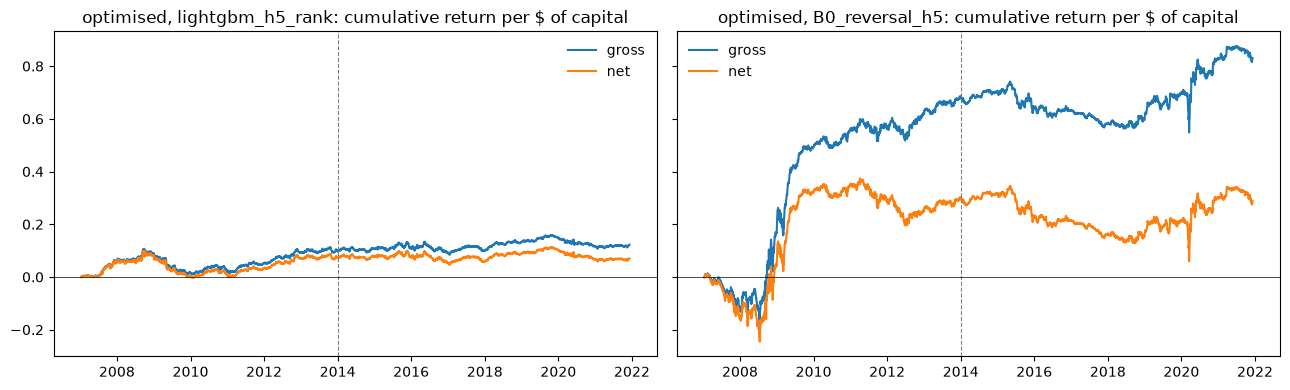

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, signal in zip(axes, ["lightgbm_h5_rank", "B0_reversal_h5"]):
    s = series[(signal, "optimised")]
    ax.plot(s.index, s["gross_pnl"].cumsum(), label="gross")
    ax.plot(s.index, s["net_pnl"].cumsum(), label="net")
    ax.axvline(SPLIT, color="grey", ls="--", lw=0.8)
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"optimised, {signal}: cumulative return per $ of capital")
    ax.legend(frameon=False)
fig.tight_layout()

## Construction ladder, evaluation window

`*_vs_previous` is the change from the rung above.

- **`decile_ls`:** every signal loses money net. This equal-weight decile book trades 15-88× a year.
- **`neutral_volscaled`:** this rung has the highest gross Sharpe for `lightgbm_h5_rank` (0.80), but it still loses net (-0.26) because it trades 54× a year.
- **`optimised`:** turnover falls to 1-10× a year and net Sharpe moves up to roughly zero, mostly because gross return falls as well.

The only positive net Sharpe in the evaluation window is B1 under `neutral_volscaled`, at 0.28 (t 0.78). It is not significant.

In [5]:
display(read("ladder").query("window == 'evaluation'"))

,signal,window,construction,gross_sharpe,net_sharpe,net_nw_t,gross_return_ann,net_return_ann,cost_ann,borrow_ann,annual_turnover,breakeven_cost_multiplier,net_return_ann_vs_previous,net_sharpe_vs_previous
0,B0_reversal_h5,evaluation,decile_ls,0.236394,-1.098935,-2.641567,0.041452,-0.192017,0.230969,0.002500,87.621933,0.177548,NaN,NaN
1,B0_reversal_h5,evaluation,neutral_volscaled,0.506758,-1.134524,-2.803753,0.036560,-0.081679,0.115759,0.002480,71.915397,0.309204,0.110338,-0.035589
2,B0_reversal_h5,evaluation,optimised,0.263295,-0.025987,-0.065464,0.018172,-0.001791,0.017561,0.002402,9.927237,0.910272,0.079888,1.108537
6,B1_composite_h5,evaluation,decile_ls,-0.039577,-0.384046,-1.104172,-0.010638,-0.103266,0.090127,0.002500,41.768921,-0.114852,NaN,NaN
7,B1_composite_h5,evaluation,neutral_volscaled,0.679031,0.282961,0.781676,0.064731,0.026976,0.035284,0.002471,29.082118,1.714501,0.130242,0.667006
8,B1_composite_h5,evaluation,optimised,-0.005996,-0.061759,-0.177422,-0.000622,-0.006410,0.003340,0.002448,2.396502,-0.107505,-0.033386,-0.344720
12,lightgbm_h21_rank,evaluation,decile_ls,0.005856,-0.212389,-0.728641,0.000935,-0.033893,0.032444,0.002383,15.118708,0.026834,NaN,NaN
13,lightgbm_h21_rank,evaluation,neutral_volscaled,0.106488,-0.129265,-0.447194,0.005924,-0.007192,0.010628,0.002489,11.314277,0.451675,0.026701,0.083124
14,lightgbm_h21_rank,evaluation,optimised,0.034771,-0.057740,-0.187752,0.001938,-0.003219,0.002679,0.002478,2.386776,0.375857,0.003973,0.071525
18,lightgbm_h5_rank,evaluation,decile_ls,0.201071,-0.545481,-1.582815,0.039961,-0.108402,0.145864,0.002499,64.154055,0.269348,NaN,NaN


## Where the costs go

Costs are in bp a year on capital. For the high-turnover constructions, impact dominates, at 1-5× the spread cost. For the low-turnover `optimised` headline book, borrow at 21 bp a year is the largest single item, more than all trading costs combined (11 bp).

,signal,construction,window,commission_bp_per_year,spread_bp_per_year,impact_bp_per_year,borrow_bp_per_year,total_cost_bp_per_year,gross_bp_per_year,net_bp_per_year,cost_per_unit_turnover_bp
0,lightgbm_h5_rank,decile_ls,evaluation,64.154055,256.616221,1137.868916,24.994916,1483.634108,399.614187,-1084.019921,11.368254
2,lightgbm_h5_rank,neutral_volscaled,evaluation,53.736477,214.945910,492.550621,24.857895,786.090903,592.297342,-193.793562,7.083019
4,lightgbm_h5_rank,optimised,evaluation,1.184854,4.739416,5.613891,21.238053,32.776214,32.426688,-0.349526,4.869022
6,B0_reversal_h5,decile_ls,evaluation,87.621933,350.487731,1871.580929,24.996815,2334.687408,414.518725,-1920.168683,13.179866
8,B0_reversal_h5,neutral_volscaled,evaluation,71.915397,287.661588,798.010121,24.799898,1182.387004,365.598226,-816.788779,8.048256
10,B0_reversal_h5,optimised,evaluation,9.927237,39.708947,125.971782,24.024442,199.632407,181.719846,-17.912561,8.844756
12,B1_composite_h5,decile_ls,evaluation,41.768921,167.075682,692.428191,25.003005,926.275798,-106.384178,-1032.659977,10.788797
14,B1_composite_h5,neutral_volscaled,evaluation,29.082118,116.328471,207.432491,24.707726,377.550805,647.311220,269.760414,6.066324
16,B1_composite_h5,optimised,evaluation,2.396502,9.586010,21.416298,24.480872,57.879682,-6.222376,-64.102058,6.968241
18,lightgbm_h21_rank,decile_ls,evaluation,15.118708,60.474832,248.845768,23.833494,348.272802,9.345724,-338.927078,10.729730


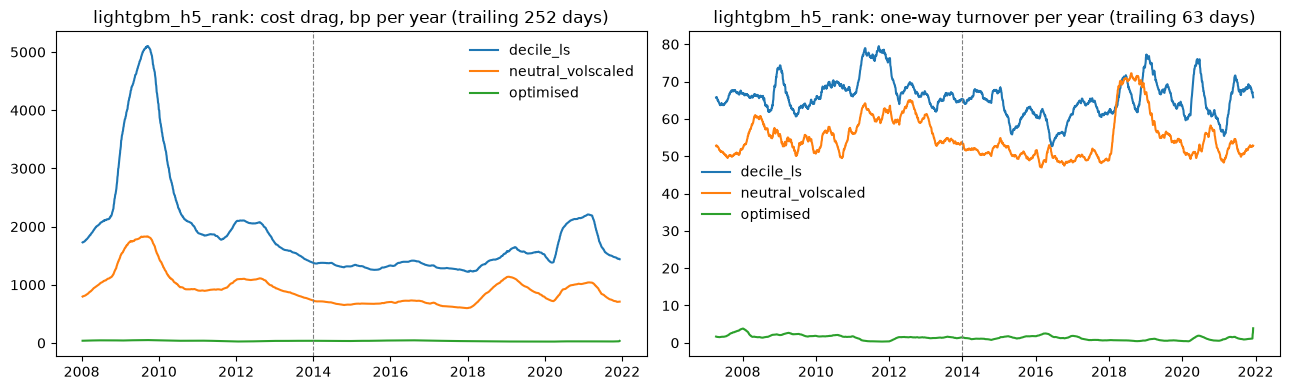

In [6]:
display(read("cost_breakdown").query("window == 'evaluation'"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for construction in ["decile_ls", "neutral_volscaled", "optimised"]:
    s = series[("lightgbm_h5_rank", construction)]
    drag = (s["cost"] + s["borrow"]).rolling(252).mean() * 252 * 1e4
    axes[0].plot(s.index, drag, label=construction)
    axes[1].plot(s.index, s["turnover"].rolling(63).mean() * 252, label=construction)
axes[0].set_title("lightgbm_h5_rank: cost drag, bp per year (trailing 252 days)")
axes[1].set_title("lightgbm_h5_rank: one-way turnover per year (trailing 63 days)")
for ax in axes:
    ax.axvline(SPLIT, color="grey", ls="--", lw=0.8)
    ax.legend(frameon=False)
fig.tight_layout()

## Exposures

Realised beta comes from regressing daily net returns on the equal-weighted universe return. The NW t-statistic uses the research lag rule. The rolling line plotted here is the 63-day beta of gross P&L.

The constraints hold ex ante: mean |β'w| is at most 0.04 for the neutral constructions. Realised beta is small but often significant, for example 0.10 (t 5.0) for B0 `optimised`. `decile_ls` is not beta-neutral by construction, and B1's decile book runs a realised beta of -0.64.

,signal,construction,window,realised_beta,realised_beta_t,mean_gross_exposure,mean_net_exposure,mean_abs_net_exposure,mean_beta_ex_ante,mean_abs_beta_ex_ante,rebalances_full_sample,fallback_hold_full_sample,fallback_flat_full_sample,fallback_partial_full_sample
0,lightgbm_h5_rank,decile_ls,evaluation,-0.088308,-0.826170,1.999030,0.000446,0.008998,-0.198052,0.346748,3760,0,0,0
2,lightgbm_h5_rank,neutral_volscaled,evaluation,0.058710,2.152448,1.988162,0.000536,0.003737,0.000837,0.005866,3760,0,0,0
4,lightgbm_h5_rank,optimised,evaluation,0.007036,1.463098,1.698056,0.000017,0.001189,-0.004589,0.007172,3760,1,0,0
6,B0_reversal_h5,decile_ls,evaluation,0.259534,3.231162,1.999185,0.000445,0.008218,-0.000038,0.244738,3760,0,0,0
8,B0_reversal_h5,neutral_volscaled,evaluation,0.122918,4.821973,1.983316,0.000330,0.003752,0.001716,0.005232,3760,0,0,0
10,B0_reversal_h5,optimised,evaluation,0.099329,5.031072,1.921077,0.000125,0.003152,-0.005299,0.023185,3760,0,0,0
12,B1_composite_h5,decile_ls,evaluation,-0.639774,-6.429720,1.999218,-0.000014,0.012307,-0.419026,0.458396,3760,0,0,0
14,B1_composite_h5,neutral_volscaled,evaluation,-0.108534,-3.864780,1.976140,0.000528,0.005003,-0.001142,0.007200,3760,0,0,0
16,B1_composite_h5,optimised,evaluation,-0.096157,-2.941619,1.957448,-0.000013,0.005010,-0.025378,0.036543,3760,0,1,0
18,lightgbm_h21_rank,decile_ls,evaluation,0.153441,1.926785,1.905378,-0.000277,0.015360,-0.043311,0.249969,3776,0,0,0


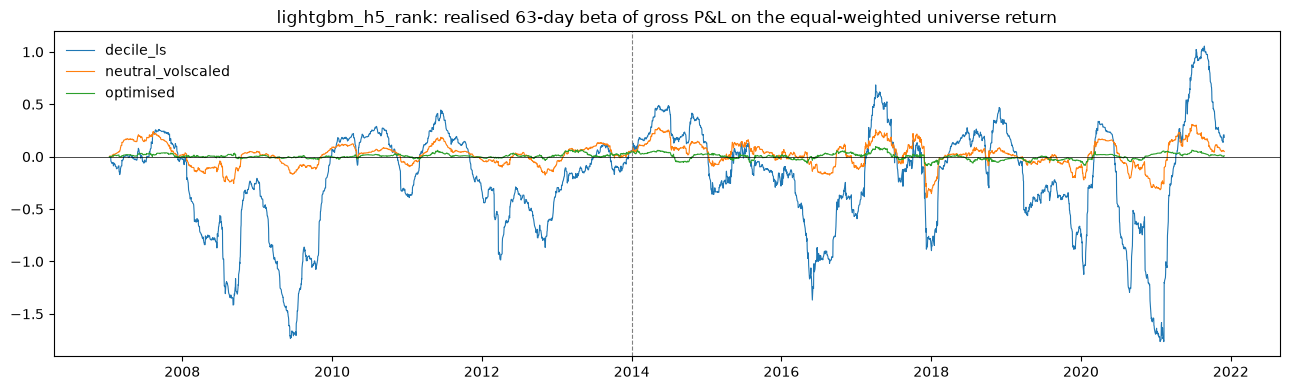

In [7]:
display(read("exposures").query("window == 'evaluation'"))
fig, ax = plt.subplots(figsize=(13, 4))
for construction in ["decile_ls", "neutral_volscaled", "optimised"]:
    s = series[("lightgbm_h5_rank", construction)]
    ax.plot(s.index, s["beta_realised"], label=construction, lw=0.8)
ax.axhline(0, color="black", lw=0.5)
ax.axvline(SPLIT, color="grey", ls="--", lw=0.8)
ax.set_title("lightgbm_h5_rank: realised 63-day beta of gross P&L on the equal-weighted universe return")
ax.legend(frameon=False)
fig.tight_layout()

## Cost multipliers and AUM

The scenarios run one dimension at a time around the base case (×1 costs, $100m). The ✕ marks the break-even multiplier, computed on the base-case trades.

The `optimised` points are not the base trades with more cost added. In each scenario the optimiser sees the scaled costs and re-solves, which is why its curve is not monotone. With zero costs it trades 15-82× a year.

,signal,construction,window,scenario,cost_multiplier,aum_usd,net_sharpe,net_nw_t,net_return_ann,gross_return_ann,cost_ann,borrow_ann,annual_turnover
1,lightgbm_h5_rank,decile_ls,evaluation,base,1.0,100000000,-0.545481,-1.582815,-0.108402,0.039961,0.145864,0.002499,64.154055
11,lightgbm_h5_rank,decile_ls,evaluation,aum_1e+07,1.0,10000000,-0.153964,-0.445226,-0.030598,0.039961,0.068060,0.002499,64.154055
13,lightgbm_h5_rank,decile_ls,evaluation,aum_1e+09,1.0,1000000000,-1.782374,-5.203554,-0.354441,0.039961,0.391903,0.002499,64.154055
15,lightgbm_h5_rank,neutral_volscaled,evaluation,base,1.0,100000000,-0.260999,-0.754712,-0.019379,0.059230,0.076123,0.002486,53.736477
25,lightgbm_h5_rank,neutral_volscaled,evaluation,aum_1e+07,1.0,10000000,0.192565,0.554963,0.014300,0.059230,0.042444,0.002486,53.736477
27,lightgbm_h5_rank,neutral_volscaled,evaluation,aum_1e+09,1.0,1000000000,-1.694231,-4.916457,-0.125882,0.059230,0.182626,0.002486,53.736477
29,lightgbm_h5_rank,optimised,evaluation,base,1.0,100000000,-0.001464,-0.004420,-0.000035,0.003243,0.001154,0.002124,1.184854
39,lightgbm_h5_rank,optimised,evaluation,aum_1e+07,1.0,10000000,-0.245394,-0.695505,-0.007592,-0.003279,0.002012,0.002300,2.719701
41,lightgbm_h5_rank,optimised,evaluation,aum_1e+09,1.0,1000000000,-0.020642,-0.060991,-0.000280,0.001404,0.000473,0.001211,0.334622
43,B0_reversal_h5,decile_ls,evaluation,base,1.0,100000000,-1.098935,-2.641567,-0.192017,0.041452,0.230969,0.002500,87.621933


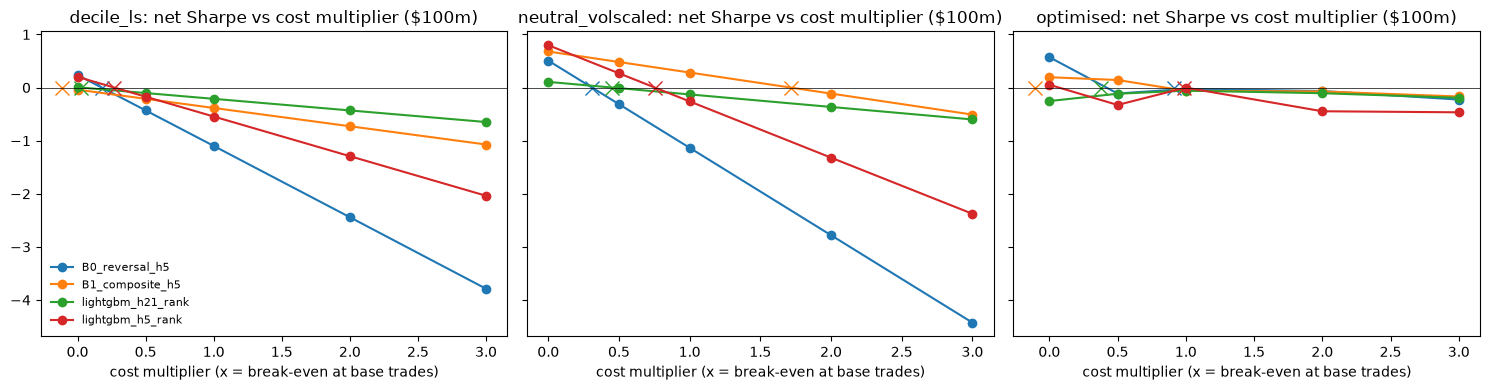

In [8]:
sc = read("scenarios").query("window == 'evaluation' and aum_usd == 1e8")
be = read("ladder").query("window == 'evaluation'").set_index(["signal", "construction"])["breakeven_cost_multiplier"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, construction in zip(axes, ["decile_ls", "neutral_volscaled", "optimised"]):
    for signal, g in sc[sc["construction"] == construction].groupby("signal"):
        g = g.sort_values("cost_multiplier")
        line, = ax.plot(g["cost_multiplier"], g["net_sharpe"], marker="o", label=signal)
        m = be.get((signal, construction), np.nan)
        if np.isfinite(m) and m <= 3.5:
            ax.plot([m], [0], marker="x", ms=10, color=line.get_color())
    ax.axhline(0, color="black", lw=0.5)
    ax.set_title(f"{construction}: net Sharpe vs cost multiplier ($100m)")
    ax.set_xlabel("cost multiplier (x = break-even at base trades)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
display(read("scenarios").query("window == 'evaluation' and cost_multiplier == 1"))

## Net Sharpe by calendar year, `optimised`

The 2007-2013 years are in the tuning window.

In [9]:
by_year = read("by_year").query("construction == 'optimised'")
display(by_year.pivot(index="year", columns="signal", values="net_sharpe").round(2))

signal,B0_reversal_h5,B1_composite_h5,lightgbm_h21_rank,lightgbm_h5_rank
year,,,,
2007,-2.29,2.60,-0.42,2.14
2008,1.11,0.44,0.14,0.58
2009,2.57,-3.39,0.20,-2.27
2010,0.47,0.41,1.21,0.09
2011,-0.78,0.42,1.37,1.17
2012,-0.46,0.85,1.16,1.72
2013,1.09,-0.29,-0.09,-0.02
2014,0.60,-0.58,0.37,0.24
2015,-1.42,-0.01,-0.65,0.01


## Conclusion

After costs, none of the 12 signal × construction books in the evaluation window has a net Sharpe significantly different from zero. Most of them are negative.

The LightGBM headline does not beat B0 after costs. Both are about zero, and the difference is not meaningful. Costs absorb the gross edge: for every book except B1 `neutral_volscaled`, the break-even multiplier at base trades is below 1.